# La muestra retenida: el error del sustituto con onnxruntime, el grafo cuantizado, y el autoencoder frente al control de envolvente

**Pregunta:** En una muestra independiente de hipercubo latino de puntos de operación, ¿qué tan precisa es cada una de las diez salidas del sustituto, qué cuesta la cuantización a 8 bits, y qué fracción de los puntos plantados fuera del dominio detecta el autoencoder junto al control de envolvente?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook usted puede:

- sortear los puntos de operación retenidos, con el mismo muestreador y la misma semilla que la evaluación del producto, y decir por qué son independientes del sorteo de entrenamiento;
- puntuar el sustituto con ellos mediante onnxruntime, salida por salida, con R cuadrado y el error porcentual absoluto medio;
- medir qué pierde el grafo de 8 bits frente al float32, y comprobar que P80 nunca baja al abrir la abertura;
- puntuar el autoencoder con puntos retenidos y con puntos plantados fuera del dominio, y poner su detección junto a la del control de envolvente.

## Preparación

Las mismas cuatro bibliotecas del notebook 01: numpy, matplotlib, onnxruntime y jsonschema.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.27.0 jsonschema==4.26.0
```

Las importaciones agregan el muestreador de la barrida y las funciones de evaluación propias del producto, que viven en la etapa de evaluación del pipeline y son públicas: la función de R cuadrado y MAPE, la comprobación de monotonía y la regla de plantado, con la función que da los objetivos de entrenamiento de un resultado.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib', 'onnxruntime', 'jsonschema'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.model import sweep
from pipeline.model.bundles import load_bundle, session_for, decode_outputs, reconstruction_score
from pipeline.model.crusher import evaluate
from pipeline.model.crusher.encoding import encode_input, ae_feats
from pipeline.stages.evaluate import r2_mape, monotonicity_check, planted_points
from pipeline.stages.train import target_vector
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.27.0
jsonschema 4.26.0


## Datos

Los dos modelos publicados. El sustituto y el autoencoder son modelos publicados de ChancaDEM, entrenados por el propio pipeline con una barrida de hipercubo latino del motor y versionados con sus contratos (`surrogate-model`, `anomaly-model`). Clase de licencia: MIT, como el resto del repositorio; los datos de entrenamiento son sintéticos, sorteados del motor. Archivos leídos: el contrato y los grafos del sustituto (`data/derived/models/surrogate.json`, `surrogate.onnx`, `surrogate.int8.onnx`) y los del autoencoder (`data/derived/models/psd-ae.json`, `psd-ae.onnx`). Las métricas retenidas que registra la etapa de evaluación del pipeline las verifica la batería de pruebas, y este notebook las calcula de nuevo.

La celda carga ambos paquetes y abre una sesión de onnxruntime por grafo.

In [2]:
# Cargue los dos paquetes validados y abra una sesión por cada grafo
models_dir = ROOT / "data" / "derived" / "models"
sbundle = load_bundle("surrogate-model", models_dir)
abundle = load_bundle("anomaly-model", models_dir)
s32 = session_for(models_dir, sbundle["graphs"]["float32"])
s8 = session_for(models_dir, sbundle["graphs"]["int8"])
sa = session_for(models_dir, abundle["graph"])
trained = sbundle["training"]
print("entrenado con", trained["n_train"], "puntos; el contrato registra una muestra retenida de", trained["n_test"])

entrenado con 6430 puntos; el contrato registra una muestra retenida de 2196


## Método

**Paso 1, la muestra retenida.** Los puntos de entrenamiento vienen de una barrida de hipercubo latino del motor con la semilla 12345, 1400 puntos por máquina. La evaluación sortea una segunda barrida independiente con la semilla 67890 y 480 puntos por máquina, no una partición de la primera, de modo que ningún punto retenido se vio en el entrenamiento. El muestreador estratifica cada una de las seis entradas continuas en el rango de su propia máquina (un giratorio nunca opera con 6 mm), y el pipeline descarta los sorteos degenerados, los que el motor marca inválidos o con una razón de reducción menor que 1,02. La celda sortea y etiqueta los puntos con el motor y cuenta las máquinas.

In [3]:
# Sortee los puntos retenidos con el muestreador y la semilla del producto, etiquételos con el motor y cuéntelos
drawn = sweep.draw(480, 67890)
held = sweep.label(drawn)
print("sorteados:", len(drawn), "| conservados tras descartar los degenerados:", len(held))
print("descartados:", len(drawn) - len(held))
print({m: sum(r.op.machine == m for r in held) for m in sweep.MACHINES})

sorteados: 2400 | conservados tras descartar los degenerados: 2196
descartados: 204
{'cone-sec': 468, 'cone-tert': 479, 'jaw': 479, 'cone-short-head': 480, 'gyratory': 290}


**Paso 2, la puntuación por salida.** La celda codifica los puntos retenidos con el codificador compartido, ejecuta el grafo float32 sobre todos en un lote, decodifica las salidas y compara cada una con el valor del motor, que es la etiqueta del profesor. La función de evaluación del producto calcula, por salida, el R cuadrado y el error porcentual absoluto medio en unidades originales (las salidas de tamaño se decodifican desde logaritmos antes de comparar).

In [4]:
# Puntúe el grafo float32 con los puntos retenidos, salida por salida
x = np.array([encode_input(r.op, sbundle["in_mean"], sbundle["in_std"]) for r in held], np.float32)
z32, z8 = s32.run(None, {"x": x})[0], s8.run(None, {"x": x})[0]
predicted32, predicted8 = decode_outputs(z32, sbundle), decode_outputs(z8, sbundle)
raw = np.array([target_vector(r) for r in held])
truth = raw.copy()
log = np.array(sbundle["out_log"], dtype=bool)
truth[:, log] = np.power(10.0, raw[:, log])
score = {}
for j, name in enumerate(sbundle["output_order"]):
    score[name] = (r2_mape(predicted32[:, j], truth[:, j]), r2_mape(predicted8[:, j], truth[:, j]))
    (r2, mape), (_, mape8) = score[name]
    print(f"{name:15s} R2 {r2:.4f}  MAPE {mape:6.2f} %  MAPE int8 {mape8:6.2f} %")

p80_mm          R2 0.9970  MAPE   4.06 %  MAPE int8   4.57 %
p50_mm          R2 0.9947  MAPE   5.73 %  MAPE int8   6.13 %
p20_mm          R2 0.9886  MAPE   9.21 %  MAPE int8   9.48 %
pass_1          R2 0.9868  MAPE   8.11 %  MAPE int8   8.33 %
pass_4          R2 0.9884  MAPE   7.70 %  MAPE int8   7.91 %
pass_8          R2 0.9930  MAPE   5.30 %  MAPE int8   5.64 %
pass_16         R2 0.9936  MAPE   5.29 %  MAPE int8   5.54 %
pass_32         R2 0.9971  MAPE   2.73 %  MAPE int8   2.87 %
throughput_tph  R2 0.9984  MAPE   5.02 %  MAPE int8   5.43 %
power_kw        R2 0.9792  MAPE   6.47 %  MAPE int8   6.43 %


La figura dibuja el P80 del sustituto contra el del motor para todos los puntos retenidos, en ejes logarítmicos porque el P80 recorre casi dos décadas, de 3 a 200 mm, entre las cinco máquinas. Un emulador perfecto queda sobre la diagonal.

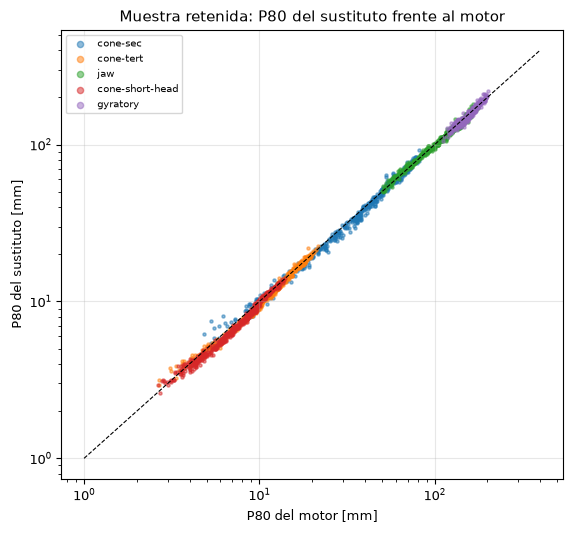

In [5]:
# Gráfico de paridad del P80 del sustituto contra el del motor en la muestra retenida, coloreado por máquina
fig, ax = plt.subplots(figsize=(5.8, 5.4))
machine = np.array([r.op.machine for r in held])
for m in sweep.MACHINES:
    pick = machine == m
    ax.scatter(truth[pick, 0], predicted32[pick, 0], s=5, alpha=0.5, label=m)
ax.plot([1, 400], [1, 400], "k--", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("P80 del motor [mm]")
ax.set_ylabel("P80 del sustituto [mm]")
ax.set_title("Muestra retenida: P80 del sustituto frente al motor")
ax.legend(fontsize=7, markerscale=2)
fig.tight_layout()
plt.show()

La nube se pega a la diagonal en todo el rango, con la dispersión visible en el extremo fino, los productos del cono de cabeza corta bajo 5 mm, donde pocos milímetros son un error relativo grande; los productos gruesos del giratorio, la máquina menos muestreada, con 290 de sus 480 sorteos sobrevivientes al filtro de degenerados frente a 468 a 480 de las otras, quedan sobre una línea estrecha. El R cuadrado de P80 es 0,997 y el MAPE 4,06 por ciento; la peor salida por MAPE es `p20_mm`, con 9,2 por ciento, la cola fina del producto, que es la parte más empinada de la distribución de tamaños. La figura muestra el error típico, no la cola de los errores; el peor punto individual puede estar mucho más lejos de la línea de lo que sugiere la nube.

**Paso 3, el costo de los 8 bits.** El contrato publicado lleva un segundo grafo, cuantizado dinámicamente a enteros de 8 bits, de la mitad del tamaño, para la vía web en vivo. La celda compara los dos grafos: la mayor diferencia absoluta de las salidas estandarizadas en toda la muestra retenida, y el MAPE medio sobre las diez salidas de cada grafo, y la figura pone lado a lado los dos valores de MAPE por salida.

mayor diferencia absoluta de las salidas estandarizadas, float32 frente a int8: 0.2349
MAPE medio, float32 e int8: 5.963 6.233


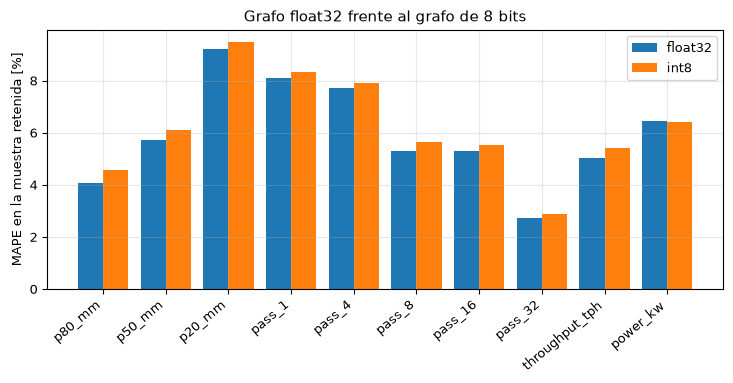

In [6]:
# Mayor diferencia estandarizada entre los dos grafos, MAPE medio de cada uno, y las barras por salida
names = list(score)
mape32 = [score[k][0][1] for k in names]
mape8 = [score[k][1][1] for k in names]
largest = float(np.max(np.abs(z32.astype(np.float64) - z8)))
print("mayor diferencia absoluta de las salidas estandarizadas, float32 frente a int8:", round(largest, 4))
print("MAPE medio, float32 e int8:", round(float(np.mean(mape32)), 3), round(float(np.mean(mape8)), 3))
fig, ax = plt.subplots()
ax.bar(np.arange(10) - 0.2, mape32, 0.4, label="float32")
ax.bar(np.arange(10) + 0.2, mape8, 0.4, label="int8")
ax.set_xticks(range(10), names, rotation=40, ha="right")
ax.set_ylabel("MAPE en la muestra retenida [%]")
ax.set_title("Grafo float32 frente al grafo de 8 bits")
ax.legend()
fig.tight_layout()
plt.show()

Las dos barras tienen casi la misma altura en cada salida, a menos de medio punto: el grafo cuantizado ocupa la mitad de los bytes con casi la misma precisión. Las salidas estandarizadas difieren hasta 0,23 en algún punto individual, razón por la que el producto informa también el peor caso y no solo la media. La potencia es la única salida en que int8 no es peor, 6,43 frente a 6,47 por ciento, un recordatorio de que el ruido de cuantización puede caer en cualquier sentido. La figura muestra solo la precisión frente al motor, no la velocidad, que es una propiedad del entorno de ejecución y de la máquina.

**Paso 4, monotonía.** Una propiedad física a la que el producto sujeta la red: el P80 no debe bajar más de 0,001 mm al abrir la abertura de lado cerrado, en tres puntos base de las otras entradas, en cada máquina. La comprobación del pipeline construye 16 aberturas a lo largo del rango de cada máquina en los percentiles 25, 50 y 75 de las otras cinco entradas, 15 curvas en total, y las ejecuta con el grafo float32.

In [7]:
# Ejecute la comprobación de monotonía de P80 frente a la abertura del pipeline en el grafo float32
monotone, curves = monotonicity_check(sbundle, s32)
print("P80 monótono en la abertura:", monotone, "| curvas comprobadas:", curves)

P80 monótono en la abertura: True | curvas comprobadas: 15


**Paso 5, el autoencoder.** El segundo modelo publicado es un autoencoder con ruido, 14-16-6-16-14, entrenado con la firma de 14 características de los resultados del motor (los logaritmos de P80, P50, P20 y F80, las cinco fracciones pasantes, la capacidad, la potencia, la razón de reducción, la energía específica y la uniformidad de la alimentación). Su error de reconstrucción es un puntaje de anomalía: un resultado lejos del dominio de entrenamiento se reconstruye mal. El umbral de alarma es el percentil 99 de los puntajes de entrenamiento, 0,24454, de modo que por construcción alrededor de 1 por ciento de los puntos dentro de la distribución da alarma. La celda puntúa los resultados retenidos e informa la tasa de falsas alarmas, y la fracción de los puntos retenidos que marca el control de envolvente.

In [8]:
# Puntúe los resultados retenidos con el autoencoder; la tasa de falsas alarmas junto a la tasa de marcas del control
threshold = abundle["threshold_p99"]
held_scores = np.array([reconstruction_score(ae_feats(r), abundle, sa) for r in held])
false_alarm = float(np.mean(~np.isfinite(held_scores) | (held_scores > threshold)))
gate_alarm = float(np.mean([r.out_of_envelope for r in held]))
print("umbral:", threshold, "| tasa de falsas alarmas del autoencoder:", round(false_alarm * 100, 1), "%")
print("el control de envolvente marca:", round(gate_alarm * 100, 1), "% de los puntos retenidos")

umbral: 0.24454 | tasa de falsas alarmas del autoencoder: 1.0 %
el control de envolvente marca: 0.0 % de los puntos retenidos


**Paso 6, puntos plantados fuera del dominio.** Un detector debe también ver un caso que debería atrapar. La regla del producto planta, para cada punto retenido, uno fuera del rango de entrenamiento de su máquina: una de las seis entradas continuas movida sobre su cota superior en la mitad del ancho del rango, o bajo su cota inferior a la mitad de ella, o dos entradas vecinas movidas en sentidos opuestos, ciclando sobre 18 patrones. El motor etiqueta luego cada punto plantado, de modo que su firma es un resultado honesto del motor en una entrada que la red nunca vio. La celda puntúa los puntos plantados con ambos detectores y dibuja las distribuciones de puntajes.

puntos plantados: 2196 | detección del autoencoder: 28.0 %
detección del control de envolvente: 13.9 %
marcados por ambos: 178 | solo el autoencoder: 436 | solo el control: 127 | ninguno: 1455
puntaje mediano, retenidos y plantados: 0.0338 0.1112


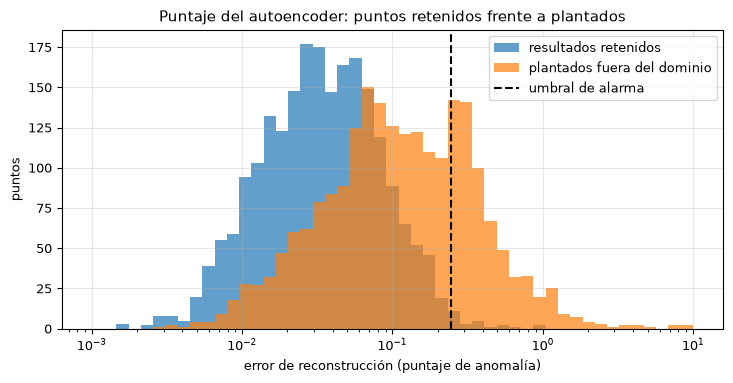

In [9]:
# Plante puntos fuera del dominio, etiquételos con el motor, puntúelos con el autoencoder y el control de envolvente, y cuente el traslape
planted = [evaluate(o) for o in planted_points(held)]
planted = [r for r in planted if all(np.isfinite(ae_feats(r)))]
planted_scores = np.array([reconstruction_score(ae_feats(r), abundle, sa) for r in planted])
flagged = ~np.isfinite(planted_scores) | (planted_scores > threshold)
detection = float(np.mean(flagged))
gated = np.array([r.out_of_envelope for r in planted])
gate_detection = float(np.mean(gated))
print("puntos plantados:", len(planted), "| detección del autoencoder:", round(detection * 100, 1), "%")
print("detección del control de envolvente:", round(gate_detection * 100, 1), "%")
print("marcados por ambos:", int((flagged & gated).sum()), "| solo el autoencoder:", int((flagged & ~gated).sum()),
      "| solo el control:", int((~flagged & gated).sum()), "| ninguno:", int((~flagged & ~gated).sum()))
medians = np.median(held_scores), np.median(planted_scores)
print("puntaje mediano, retenidos y plantados:", round(float(medians[0]), 4), round(float(medians[1]), 4))
fig, ax = plt.subplots()
bins = np.logspace(-3, 1, 50)
ax.hist(held_scores, bins=bins, alpha=0.7, label="resultados retenidos")
ax.hist(planted_scores, bins=bins, alpha=0.7, label="plantados fuera del dominio")
ax.axvline(threshold, color="k", ls="--", label="umbral de alarma")
ax.set_xscale("log")
ax.set_xlabel("error de reconstrucción (puntaje de anomalía)")
ax.set_ylabel("puntos")
ax.set_title("Puntaje del autoencoder: puntos retenidos frente a plantados")
ax.legend()
fig.tight_layout()
plt.show()

Los puntos plantados están desplazados a la derecha, con un puntaje mediano de 0,111 frente a 0,034 de los resultados retenidos, pero los dos histogramas se traslapan mucho y solo la cola derecha de los plantados cruza el umbral. El autoencoder detecta 28,0 por ciento de los puntos plantados frente a 13,9 por ciento que marca el control de envolvente, de modo que agrega una señal que el control de envolvente no tiene, y aun así se le escapan siete de cada diez. El traslape impreso arriba muestra que las dos señales difieren: 178 puntos plantados quedan marcados por ambos, 436 solo por el autoencoder, 127 solo por el control de envolvente y 1455 por ninguno. La razón se ve en la construcción: el detector mira la firma del resultado del motor, y una entrada movida fuera de rango puede dar un resultado perfectamente común, porque el motor satura (el tope de t10, por ejemplo). La figura muestra que el detector es informativo y no suficiente; no debe leerse como una garantía de que un punto sin alarma está dentro del dominio.

## Resultados

**Respuesta:** en la muestra retenida de 2196 puntos de operación (2400 sorteados, 204 degenerados descartados), el sustituto reproduce al motor con R cuadrado entre 0,979 (potencia) y 0,998 (capacidad) y un MAPE entre 2,73 por ciento (`pass_32`) y 9,21 por ciento (`p20_mm`), con P80 en R cuadrado 0,997 y 4,06 por ciento. El grafo de 8 bits cuesta a lo más medio punto de MAPE por salida a cambio de la mitad de los bytes. El P80 es monótono en la abertura en las 15 curvas. El autoencoder da alarma en 1,0 por ciento de los puntos retenidos por construcción y detecta 28,0 por ciento de los puntos plantados fuera del dominio, frente a 13,9 por ciento del control de envolvente, que no marca ninguno de los puntos retenidos.

La primera figura muestra la precisión entre máquinas, la tercera la debilidad del detector. Un validador concluiría que el sustituto es preciso frente a su profesor, el motor, a cerca de 5 por ciento en promedio y monótono donde la física lo exige, y que el autoencoder es una salvaguarda parcial: útil, complementaria del control de envolvente (127 puntos plantados quedan marcados solo por el control y 436 solo por el autoencoder), y muda en siete de cada diez puntos plantados. Ninguna de las dos mediciones involucra una planta: ambas comparan una red con el motor que la entrenó. El notebook 03 pone al sustituto frente a los muestreos medidos.

## Resumen

Un modelo aprendido es tan bueno como la pregunta con que se le examina. Frente a su profesor en una muestra independiente, el sustituto es preciso y monótono y su grafo cuantizado es casi gratis; el autoencoder detecta algunas de las anomalías plantadas y el control de envolvente otras. Las mediciones comparten un límite, que comparan la red con el motor. El notebook 03 hace la pregunta que decide si un sustituto es útil para la planta: qué dice de los diez muestreos.

## Referencias

- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193